Параметры модели:
  coef      = 2.9996   (истина: 3)
  intercept = 2.1411   (истина: 2)

Метрики на TRAIN:
  MSE  :     2.1553
  RMSE :     1.4681
  MAE  :     1.2054
  R2   :     0.9736

Метрики на TEST:
  MSE  :     1.7953
  RMSE :     1.3399
  MAE  :     1.1240
  R2   :     0.9740


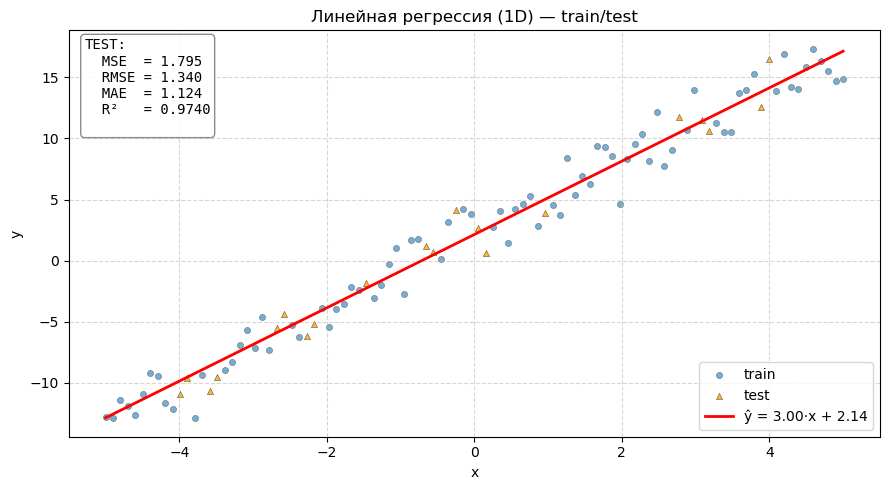

In [17]:
import numpy as np


class LinearRegression:

    def __init__(self, lr=0.01, n_iters=1000, fit_intercept=True,
                 tol=1e-8, verbose = False ):
        self.lr = lr
        self.n_iters = n_iters
        self.fit_intercept = fit_intercept
        self.tol = tol
        self.verbose = verbose

        self.coef = None
        self.intercept = None
        self.loss_history = []


    def _add_bias(self, X):
        if self.fit_intercept:
            return np.hstack([np.ones((X.shape[0], 1)), X])
        return X


    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float).reshape(-1)
        X_b = self._add_bias(X)

        n_samples, n_features = X_b.shape
        w = np.zeros(n_features)
        self.loss_history = []

        for i in range(self.n_iters):
            y_pred = X_b @ w
            error = y_pred - y


            grad = (2.0 / n_samples) * (X_b.T @ error)
            w -= self.lr * grad

            loss = np.mean(error ** 2)
            self.loss_history.append(loss)

            if self.verbose and (i % 100 == 0 or i == self.n_iters - 1):
                print(f"iter {i:5d} | MSE = {loss:.6f}")

            if self.tol is not None and np.linalg.norm(grad) < self.tol:
                if self.verbose:
                    print(f"Сходимость достигнута на итерации {i}")
                break

        if self.fit_intercept:
            self.intercept = w[0]
            self.coef = w[1:]
        else:
            self.intercept = 0.0
            self.coef = w
        return self


    def predict(self, X):
        X = np.asarray(X, dtype=float)
        return X @ self.coef + self.intercept



class Metrics:
    @staticmethod
    def mse(y_true, y_pred):
        return np.mean((np.asarray(y_true) - np.asarray(y_pred)) ** 2)

    @staticmethod
    def rmse(y_true, y_pred):
        return np.sqrt(Metrics.mse(y_true, y_pred))

    @staticmethod
    def mae(y_true, y_pred):
        return np.mean(np.abs(np.asarray(y_true) - np.asarray(y_pred)))

    @staticmethod
    def r2(y_true, y_pred):
        y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
        ss_res = np.sum((y_true - y_pred) ** 2)
        ss_tot = np.sum((y_true - y_true.mean()) ** 2)
        return 1 - ss_res / ss_tot



    @staticmethod
    def evaluate(y_true, y_pred):
        return {
            "MSE": Metrics.mse(y_true, y_pred),
            "RMSE": Metrics.rmse(y_true, y_pred),
            "MAE": Metrics.mae(y_true, y_pred),
            "R2": Metrics.r2(y_true, y_pred)
        }

import numpy as np
import matplotlib.pyplot as plt

#y = 3x + 2 + шум
rng = np.random.default_rng(0)
x = np.linspace(-5, 5, 100).reshape(-1, 1)
y = 3 * x.ravel() + 2 + rng.normal(0, 1.5, size=100)

n = len(x)
idx = rng.permutation(n)
n_train = int(0.8 * n)
train_idx, test_idx = idx[:n_train], idx[n_train:]

x_train, y_train = x[train_idx], y[train_idx]
x_test,  y_test  = x[test_idx],  y[test_idx]


model_1d = LinearRegression(lr=0.05, n_iters=2000).fit(x_train, y_train)

print("Параметры модели:")
print(f"  coef      = {model_1d.coef[0]:.4f}   (истина: 3)")
print(f"  intercept = {model_1d.intercept:.4f}   (истина: 2)")


y_train_pred = model_1d.predict(x_train)
y_test_pred  = model_1d.predict(x_test)

print("\nМетрики на TRAIN:")
for name, value in Metrics.evaluate(y_train, y_train_pred).items():
    print(f"  {name:5s}: {value:10.4f}")

print("\nМетрики на TEST:")
test_metrics = Metrics.evaluate(y_test, y_test_pred)
for name, value in test_metrics.items():
    print(f"  {name:5s}: {value:10.4f}")


x_line = np.linspace(-5, 5, 200).reshape(-1, 1)

plt.figure(figsize=(9, 5))
plt.scatter(x_train, y_train, s=20, alpha=0.6,
            label="train", edgecolor="k", linewidth=0.3)
plt.scatter(x_test, y_test, s=20, alpha=0.8,
            color="orange", marker="^",
            label="test", edgecolor="k", linewidth=0.3)
plt.plot(x_line, model_1d.predict(x_line), "r-", lw=2,
         label=f"ŷ = {model_1d.coef[0]:.2f}·x + {model_1d.intercept:.2f}")


text = (
    f"TEST:\n"
    f"  MSE  = {test_metrics['MSE']:.3f}\n"
    f"  RMSE = {test_metrics['RMSE']:.3f}\n"
    f"  MAE  = {test_metrics['MAE']:.3f}\n"
    f"  R²   = {test_metrics['R2']:.4f}\n"
)
plt.text(0.02, 0.98, text, transform=plt.gca().transAxes,
         va="top", ha="left", fontsize=10, family="monospace",
         bbox=dict(boxstyle="round", facecolor="white",
                   edgecolor="gray", alpha=0.9))

plt.xlabel("x")
plt.ylabel("y")
plt.title("Линейная регрессия (1D) — train/test")
plt.legend(loc="lower right")
plt.grid(True, ls="--", alpha=0.5)
plt.tight_layout()
plt.show()